In [1]:
import pandas as pd
import numpy as np
from plotnine import *
import pandas as pd
import numpy as np
from tqdm import tqdm
from Bio.Seq import Seq
%matplotlib inline

In [6]:
y_lookup_sanitized = pd.read_pickle('./lookup_tables/y.lookup.corrected.pkl')
st_lookup_sanitized = pd.read_pickle('./lookup_tables/st.lookup.corrected.pkl')

In [2]:
st_lookup_table_230129 = pd.read_pickle('../screening_analysis/st_lookup_table_230129.pkl')

In [7]:
st_lookup_sanitized

,identifier,length,seq,barcode_seq,ksregion,substrate,kinase,substrate_aa,kinase_aa,kinase_type,kinase_name,kinase_acc
0,m64076_231104_154224/7080654/ccs,1683,TAGCAGTATCGAGTATCCGGCTCGTATGTTGTGTGGAATTGTGCGT...,ATCAACTCGGCCCCACTAG,TTACAAGATTTGGTTAATAGAACTCCATGGAAGAAATGTTGCTTTG...,TTACAAGATTTGGTTAATAGAACTCCATGGAAGAAATGTTGCTTT,TACGAACCCAAAGAAATTCTTGGCAGAGGTGTTTCTTCGGTGGTTA...,LQDLVNRTPWKKCCF,YEPKEILGRGVSSVVRRCIHKPTSQEYAVKVIDVTGGGSFSPEEVR...,ST,PHKG1_HUMAN,Q16816
1,m64076_231104_154224/22153045/ccs,1683,TAGCAGTATCGAGTATCCGGCTCGTATGTTGTGTGGAATTGTGCGT...,AGCGCTTAGCGGTACGAGG,AAGATTAAACAAGAAGTTGAGTCACCAACTGATAAATCTGGTAATG...,AAGATTAAACAAGAAGTTGAGTCACCAACTGATAAATCTGGTAAT,TACGAACCCAAAGAAATTCTTGGCAGAGGTGTTTCTTCGGTGGTTA...,KIKQEVESPTDKSGN,YEPKEILGRGVSSVVRRCIHKPTSQEYAVKVIDVTGGGSFSPEEVR...,ST,PHKG1_HUMAN,Q16816
2,m64076_231104_154224/25954482/ccs,1633,TAGCAGTATCGAGTATCCGGCTCGTATGTTGTGTGGAATTGTGCGT...,AAACAGGCGGTTAAAGAGG,GAACCTCCAAGTCCACCCCAATCTCCGAGAGCAGAGGGTGCTTCAG...,GAACCTCCAAGTCCACCCCAATCTCCGAGAGCAGAGGGTGCTTCA,TATCAAGTTGGCCCATTGTTAGGTTCAGGTGGTTTCGGCTCCGTTT...,EPPSPPQSPRAEGAS,YQVGPLLGSGGFGSVYSGIRVSDNLPVAIKHVEKDRISDWGELPNG...,ST,PIM1_HUMAN,P11309
3,m64076_231104_154224/37423750/ccs,1662,TAGCAGTATCGAGTATCCGGCTCGTATGTTGTGTGGAATTGTGCGT...,ATTTCGCACAAAAGTGTAG,TCTTTATCATGGCCATCCAATACTAGAAAACAAATTACATTTTTGG...,TCTTTATCATGGCCATCCAATACTAGAAAACAAATTACATTTTTG,TTTGAATTGCTGAGAGTGTTAGGTAAAGGAGGCTACGGGAAGGTAT...,SLSWPSNTRKQITFL,FELLRVLGKGGYGKVFQVRKVTGANTGKIFAMKVLKKAMIVRNAKD...,ST,KS6B1_HUMAN_active,P23443
4,m64076_231104_154224/45286009/ccs,1683,TAGCAGTATCGAGTATCCGGCTCGTATGTTGTGTGGAATTGTGCGT...,ACCTCTAGGGTCGGCAGCG,GAGGTCGAAACACCTAATTCTACCCCACCCAGGAGAGTTCAAACTG...,GAGGTCGAAACACCTAATTCTACCCCACCCAGGAGAGTTCAAACT,TACGAACCCAAAGAAATTCTTGGCAGAGGTGTTTCTTCGGTGGTTA...,EVETPNSTPPRRVQT,YEPKEILGRGVSSVVRRCIHKPTSQEYAVKVIDVTGGGSFSPEEVR...,ST,PHKG1_HUMAN,Q16816
...,...,...,...,...,...,...,...,...,...,...,...,...
121065,m64076_231104_154224/52953335/ccs,1683,TAGCAGTATCGAGTATCCGGCTCGTATGTTGTGTGGAATTGTGCGT...,ATGAGGCCAATCAACCCCG,ACTTCTAGAGGAAGGAAAATGACAGTTAATGGTGCTCCTGTACCAG...,ACTTCTAGAGGAAGGAAAATGACAGTTAATGGTGCTCCTGTACCA,TACGAACCCAAAGAAATTCTTGGCAGAGGTGTTTCTTCGGTGGTTA...,TSRGRKMTVNGAPVP,YEPKEILGRGVSSVVRRCIHKPTSQEYAVKVIDVTGGGSFSPEEVR...,ST,PHKG1_HUMAN,Q16816
121066,m64076_231104_154224/60555700/ccs,1659,TAGCAGTATCGAGTATCCGGCTCGTATGTTGTGTGGAATTGTGCGT...,ACCGGAATGCATCTCCGGG,TCTAATTTAAACAATATGTCAACTACAGAGGAATATTTGATTTCCG...,TCTAATTTAAACAATATGTCAACTACAGAGGAATATTTGATTTCC,TTCAAGTTTGGAAAGATTTTGGGAGAGGGGTCGTTCTCAACAGTTG...,SNLNNMSTTEEYLIS,FKFGKILGEGSFSTVVLARELATSREYAIKILEKRHIIKENKVPYV...,ST,PDPK1_HUMAN,O15530
121067,m64076_231104_154224/60555771/ccs,1718,TAGCAGTATCGAGTATCCGGCTCGTATGTTGTGTGGAATTGTGCGT...,ATGCACGTTCCACGCCGGG,TCTGCTGTTTATGTCTTGTCCTCAATGGCCAGACAAAGAAGGGCAG...,TCTGCTGTTTATGTCTTGTCCTCAATGGCCAGACAAAGAAGGGCA,TATAAATTGCAGAGTGAAATTGGAAAAGGAGCTTACGGTGTAGTAA...,SAVYVLSSMARQRRA,YKLQSEIGKGAYGVVRLAYNESEDRHYAMKVLSKKKLLKQYGFPRR...,ST,KKCC1_HUMAN,Q8N5S9
121068,m64076_231104_154224/60555884/ccs,1697,TAGCAGTATCGAGTATCCGGCTCGTATGTTGTGTGGAATTGTGCGT...,ACTACCTCCTCGCTATATA,CAAGGTAAAACTAGAGATGATTCTGCTGACTATATTCCACATGATG...,CAAGGTAAAACTAGAGATGATTCTGCTGACTATATTCCACATGAT,TTCGACACTATTAAACTAATCTCGAATGGAGCCTACGGCGCAGTAT...,QGKTRDDSADYIPHD,FDTIKLISNGAYGAVYLVRHRDTRQRFAMKKINKQNLILRNQIQQA...,ST,MAST1_HUMAN,Q9Y2H9


In [5]:
st_lookup_table_230129['kinase_aa'].iloc[-1]

'GKGSFGQVAKCLDHKNNELVALKIIRNKKRFHQQALMELKILEALRKKDKDNTYNVVHMKDFFYFRNHFCITFELLGINLYELMKNNNFQGFSLSIVRRFTLSVLKCLQMLSVEKIIHCDLKPENIVLYQKGQASVKVIDFGSSCYEHQKVYTYIQSRFYRSPEVILGHPYDVAIDMWSLGCITAELYTGYPLFPGENEVEQLACIMEVLGLPPAGFIQTASRRQTFFDSKGFPKNITNNRGKKRYPDSKDLTMVLKTYDTSFLDFLRRCLVWEPSLRMTPDQALKHAWI'

## process blib screening data

In [20]:
st_lookup_sanitized.groupby('kinase_aa').count().reset_index().sort_values('identifier').tail(20)

,kinase_aa,identifier,length,seq,barcode_seq,ksregion,substrate,kinase,substrate_aa,kinase_type,kinase_name,kinase_acc
1374,YEPKEILGRGVSSVVRRCIHKPTSQEYTVKVIDVTGGGSFSPEEVR...,10,10,10,10,10,10,10,10,0,0,0
754,LIFNESLGQGTFTKIFKGVRREVGDYGQLHETEVLLKVLDKAHRNY...,13,13,13,13,13,13,13,13,13,13,13
757,LVLGEQIGRGNFGEVFSGRLRADNTLVAVKSCRETLPPDLKAKFLQ...,14,14,14,14,14,14,14,14,14,14,14
752,IQLLKRLGSGQFGEVWEGLWNNTTPVAVKTLKPGSMDPNDFLREAQ...,18,18,18,18,18,18,18,18,18,18,18
892,WKGSFGQVAKCLDHKNNELVALKIIRNKKRFHQQALMELKILEALR...,20,20,20,20,20,20,20,20,0,0,0
1535,YMIAEDLGRGEFGIVHRCVETSSKKTYMAKFVKVKGTDQVLVKKEI...,1805,1805,1805,1805,1805,1805,1805,1805,1805,1805,1805
925,WLLSDILGQGATANVFRGRHKKTGDLFAIKVFNNISFLRPVDVQMR...,2977,2977,2977,2977,2977,2977,2977,2977,2977,2977,2977
851,WEMKERLGTGGFGNVIRWHNQETGEQIAIKQCRQELSPRNRERWCL...,3111,3111,3111,3111,3111,3111,3111,3111,3111,3111,3111
773,SFDDTPLGTASLAQVHKAVLHDGRTVAVKVQHPKVRAQSSKDILLM...,3583,3583,3583,3583,3583,3583,3583,3583,3583,3583,3583
726,IEVEEVVGRGAFGVVCKAKWRAKDVAIKQIESESERKAFIVELRQL...,3863,3863,3863,3863,3863,3863,3863,3863,3863,3863,3863


In [96]:
blib_sample_ls = ['blib1_2batch_rra','blib2_2batch_rra','blib3_2batch_rra','blib5_2batch_rra']
paabds = ['fha','1433','ww','sh2']
kinase_type = ['ST','ST','ST','Y']
lookup_sanitized_ls = [st_lookup_sanitized,st_lookup_sanitized,st_lookup_sanitized,y_lookup_sanitized]

dat_all = []

COUNT_DIR = "${KSI_DATA_ROOT}/processed_count_table/"
for i in range(len(blib_sample_ls)):
    ftag = blib_sample_ls[i]
    lib_tag = ftag.split('_')[0]
    lookup_sanitized = lookup_sanitized_ls[i]
    print(kinase_type[i])
    dat = pd.read_csv(COUNT_DIR +ftag+ ".gene_summary.txt",sep = '\t')
    dat_count = pd.read_csv(COUNT_DIR +ftag+ ".sgrna_summary.txt",sep = '\t')
    
    dat = pd.merge(dat,dat_count,left_on = 'id',right_on = 'Gene')
    dat = dat.loc[dat['id'].apply(lambda s: len(s)== 19),:]
    dat = pd.merge(dat,lookup_sanitized,left_on = 'id',right_on = 'barcode_seq')
    dat = dat.loc[dat['control_mean']>10,:]
    print("number of barcode captured by lookup table: " + str(dat['id'].isin(lookup_sanitized['barcode_seq']).sum()/dat.shape[0]))
    dat['paabd'] = paabds[i]
    dat = dat.loc[dat['kinase_type'] == kinase_type[i],:]

    dat_count_raw = pd.read_csv('${KSI_DATA_ROOT}/processed_count_table/bliballvariant12' + lib_tag + '.count.txt',sep = '\t').iloc[:,1:]
    dat_count_raw.columns = ['barcode_seq','pre_1','mtx_1','pre_2','mtx_2']
    dat = pd.merge(dat,dat_count_raw)
    dat_all.append(dat)

ST
number of barcode captured by lookup table: 1.0
ST
number of barcode captured by lookup table: 1.0
ST
number of barcode captured by lookup table: 1.0
Y
number of barcode captured by lookup table: 1.0


In [85]:
dat_all_blib = pd.concat(dat_all)

In [86]:
# checking that the bijection of the barcodes still hold
dat_all_blib_y = dat_all_blib.loc[dat_all_blib['kinase_type']=='Y',:]
dat_all_blib_y_nr = dat_all_blib_y.drop_duplicates(['kinase_name','substrate_aa','barcode_seq','paabd'])
dat_all_blib_y_nr.groupby('barcode_seq').count().reset_index().sort_values('id')

,barcode_seq,id,num,neg|score,neg|p-value,neg|fdr,neg|rank,neg|goodsgrna,neg|lfc,pos|score,...,substrate_aa,kinase_aa,kinase_type,kinase_name,kinase_acc,paabd,pre_1,mtx_1,pre_2,mtx_2
0,AAAAAAAACTCGTGGTAGG,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
1,AAAAAAAAGCATACAGACG,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
2,AAAAAAAAGTAAACATGCG,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
3,AAAAAAAATAGTCTCTGGG,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
4,AAAAAAAATCGATCCTCAG,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82768,GGCAAAAGGAGAAAAGAGG,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
82769,GTGGCCTCCCCCACCCCGG,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
82770,GTGTAACCGAGAAATCATG,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
82771,GTTCATTGAGTATGTTACG,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1


In [87]:
dat_all_blib_st = dat_all_blib.loc[dat_all_blib['kinase_type']=='ST',:]
dat_all_blib_st_nr = dat_all_blib_st.drop_duplicates(['kinase_name','substrate_aa','barcode_seq','paabd'])
dat_all_blib_st_nr.groupby('barcode_seq').count().reset_index().sort_values('id')

,barcode_seq,id,num,neg|score,neg|p-value,neg|fdr,neg|rank,neg|goodsgrna,neg|lfc,pos|score,...,substrate_aa,kinase_aa,kinase_type,kinase_name,kinase_acc,paabd,pre_1,mtx_1,pre_2,mtx_2
34,AAAAAACGTGTCCAGTGGG,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
32,AAAAAACGGCAGATAGAGG,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
26,AAAAAACCGGTGTCTTAAG,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
85607,GTCGCGGTCCACAGAGCCG,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
22677,ACAATGACTGTGGTACCCG,1,1,1,1,1,1,1,1,1,...,1,1,1,1,1,1,1,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5,AAAAAAACCGCCATCACAG,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
4,AAAAAAAATTTACGTAATG,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
85610,GTTTTGATTGGTGGCGCTG,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3
3,AAAAAAAATTACTTGCCCG,3,3,3,3,3,3,3,3,3,...,3,3,3,3,3,3,3,3,3,3


In [88]:
dat_all_blib_nr = pd.concat([dat_all_blib_y_nr,dat_all_blib_st_nr])

In [89]:
dat_all_blib_nr.to_pickle("./dat_all_blib_2batch.pkl")

In [90]:
dat_all_blib_nr.to_csv("./dat_all_blib_2batch.csv")

## there are still some where a barcode_seq corresponding to multiple nt sequences, but on aa level it is bijected

In [3]:
dat_all_blib = pd.read_pickle("./dat_all_blib_2batch.pkl")

In [4]:
dat_all_blib['kinase_name'].drop_duplicates()

0              TNK1_HUMAN
3               FRK_HUMAN
9            JAK2_HUMAN_1
13            STYK1_HUMAN
21              FES_HUMAN
31             ABL2_HUMAN
50              FYN_HUMAN
58             KSYK_HUMAN
0             MAST1_HUMAN
1             ADCK1_HUMAN
9             PDPK1_HUMAN
14            PHKG1_HUMAN
15         KS6B1_HUMAN_wt
16            TITIN_HUMAN
22             KGP1_HUMAN
33            KKCC1_HUMAN
36      PLK1_HUMAN_active
51             PLK1_HUMAN
60             M3K7_HUMAN
67             TBK1_HUMAN
249            IKKB_HUMAN
289    KS6B1_HUMAN_active
297            PIM1_HUMAN
Name: kinase_name, dtype: object

/opt/conda/envs/pytorch_env/lib/python3.11/site-packages/plotnine/themes/themeable.py:2486: FutureWarning: You no longer need to use subplots_adjust to make space for the legend or text around the panels. This parameter will be removed in a future version. You can still use 'plot_margin' 'panel_spacing' for your other spacing needs.


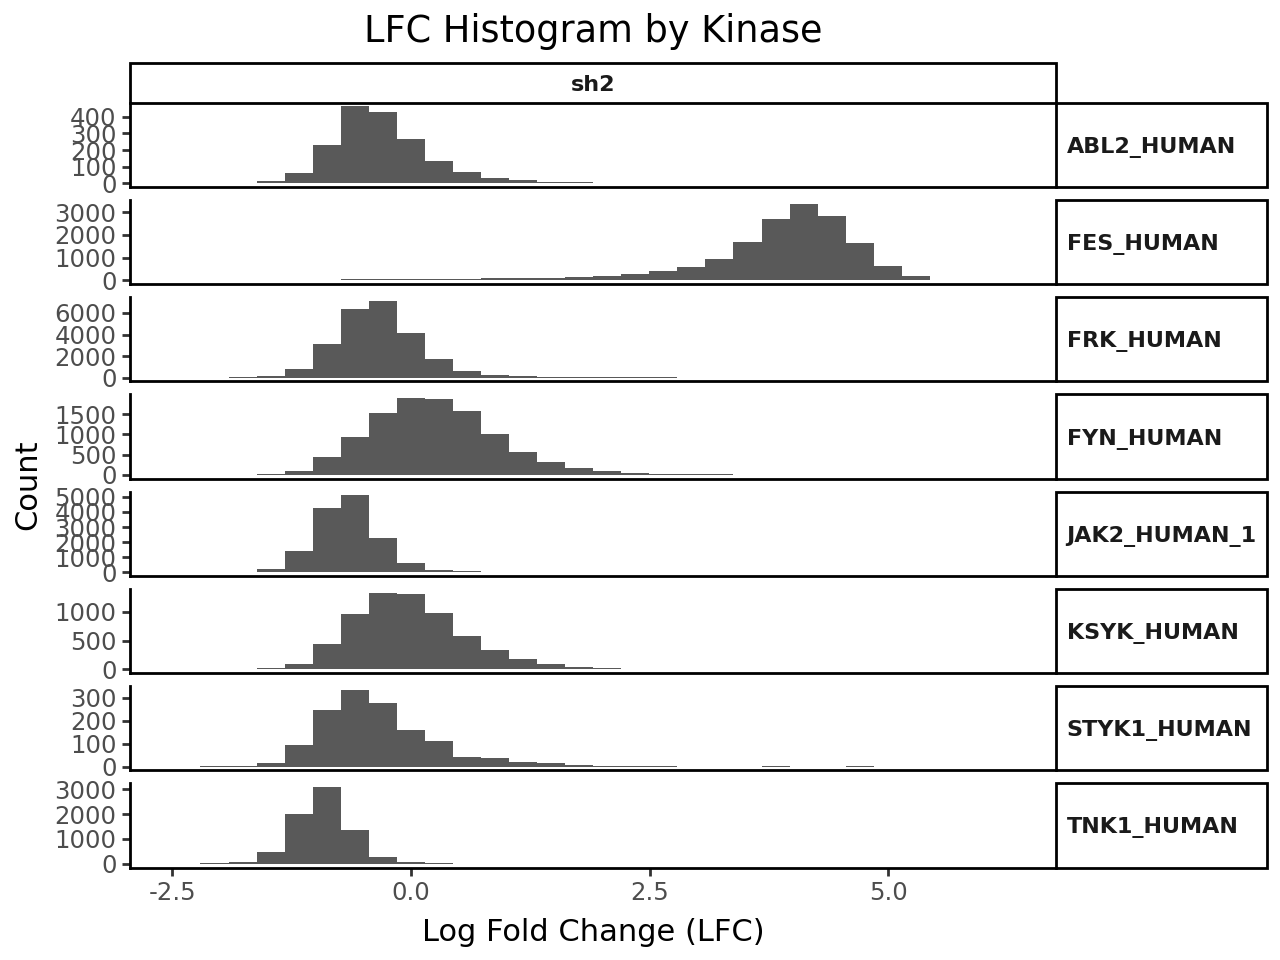

In [92]:
p = ( ggplot( dat_all_blib.loc[dat_all_blib['kinase_type']=='Y',:].dropna(subset=['kinase_name', 'LFC']), # keep it tidy 
              aes(x='LFC') ) + geom_histogram(bins=30) # adjust bins as you like 
      + facet_grid(rows = ['kinase_name'], cols=['paabd'], scales='free_y') 
      + labs( title='LFC Histogram by Kinase', x='Log Fold Change (LFC)', y='Count' ) 
      + theme_classic() 
      + theme(subplots_adjust={'wspace': 0.25}) 
      + theme(
        strip_text_y=element_text(size=8, weight='bold', rotation=0, ha='left', va='center'),
        strip_text_x=element_text(size=8, weight='bold')  # keep x-strip sizing consistent
    )
    )

p              

/opt/conda/envs/pytorch_env/lib/python3.11/site-packages/plotnine/layer.py:293: PlotnineWarning: stat_bin : Removed 94 rows containing non-finite values.
/opt/conda/envs/pytorch_env/lib/python3.11/site-packages/plotnine/layer.py:374: PlotnineWarning: geom_histogram : Removed 45 rows containing missing values.


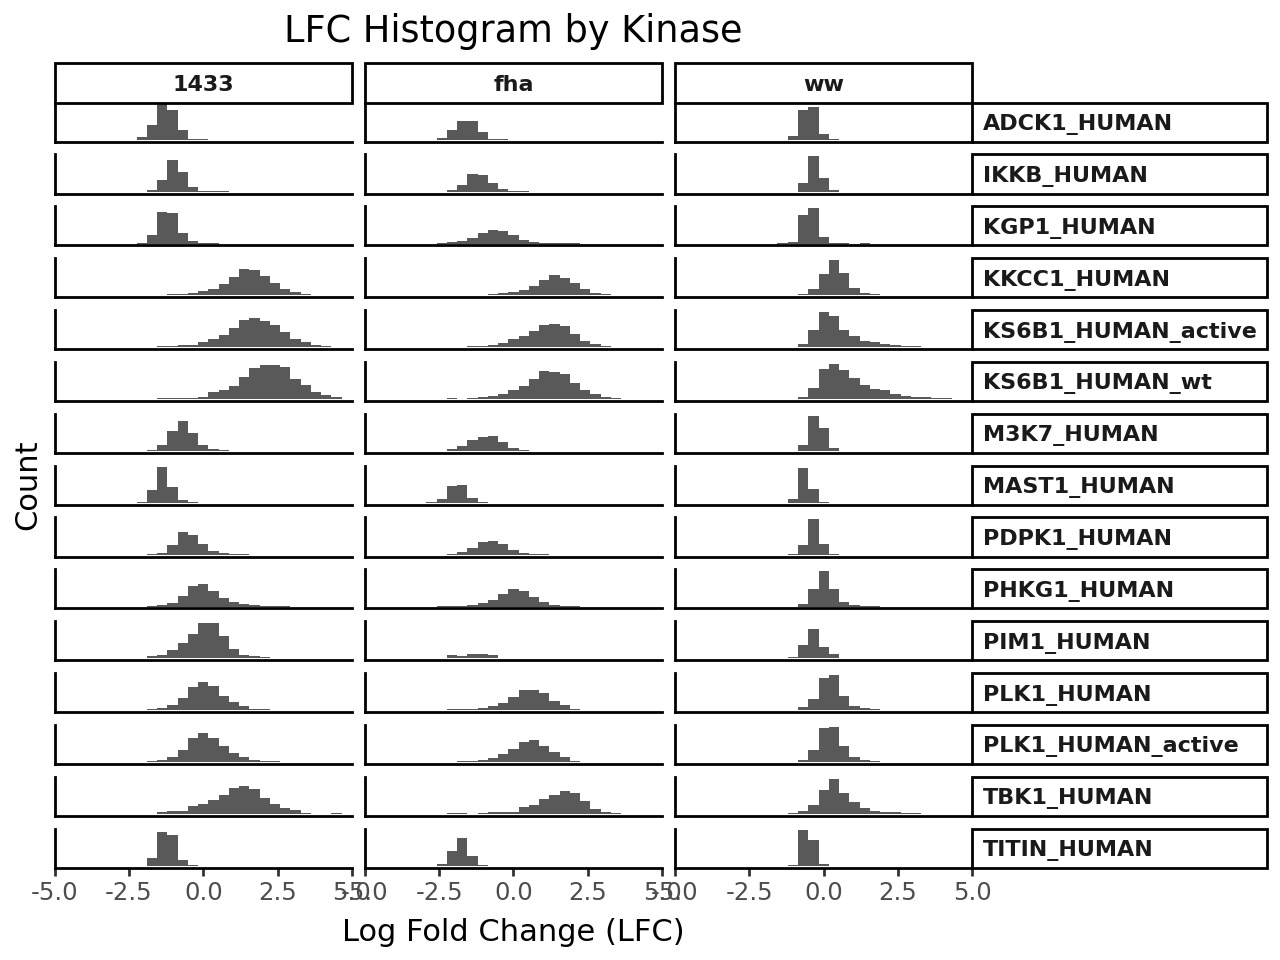

In [93]:
p = ( ggplot( dat_all_blib.loc[dat_all_blib['kinase_type']!='Y',:].dropna(subset=['kinase_name', 'LFC']), # keep it tidy 
              aes(x='LFC') ) + geom_histogram(bins=30) # adjust bins as you like 
      + facet_grid(rows = ['kinase_name'], cols=['paabd'], scales='free_y') 
      + labs( title='LFC Histogram by Kinase', x='Log Fold Change (LFC)', y='Count' ) 
      + theme_classic() 
      + theme(
        strip_text_y=element_text(size=8, weight='bold', rotation=0, ha='left', va='center'),
        strip_text_x=element_text(size=8, weight='bold')  # keep x-strip sizing consistent
    )
    )

p = (
    p
    + scale_x_continuous(limits=(-5,5), expand=(0, 0))
    + theme(
        axis_text_y=element_blank(),          # remove y tick labels
        axis_ticks_major_y=element_blank(),   # remove major y tick marks
        axis_ticks_minor_y=element_blank()    # remove minor y tick marks
    )
)
p

/opt/conda/envs/pytorch_env/lib/python3.11/site-packages/plotnine/layer.py:293: PlotnineWarning: stat_bin : Removed 527 rows containing non-finite values.
/opt/conda/envs/pytorch_env/lib/python3.11/site-packages/plotnine/layer.py:374: PlotnineWarning: geom_histogram : Removed 4 rows containing missing values.


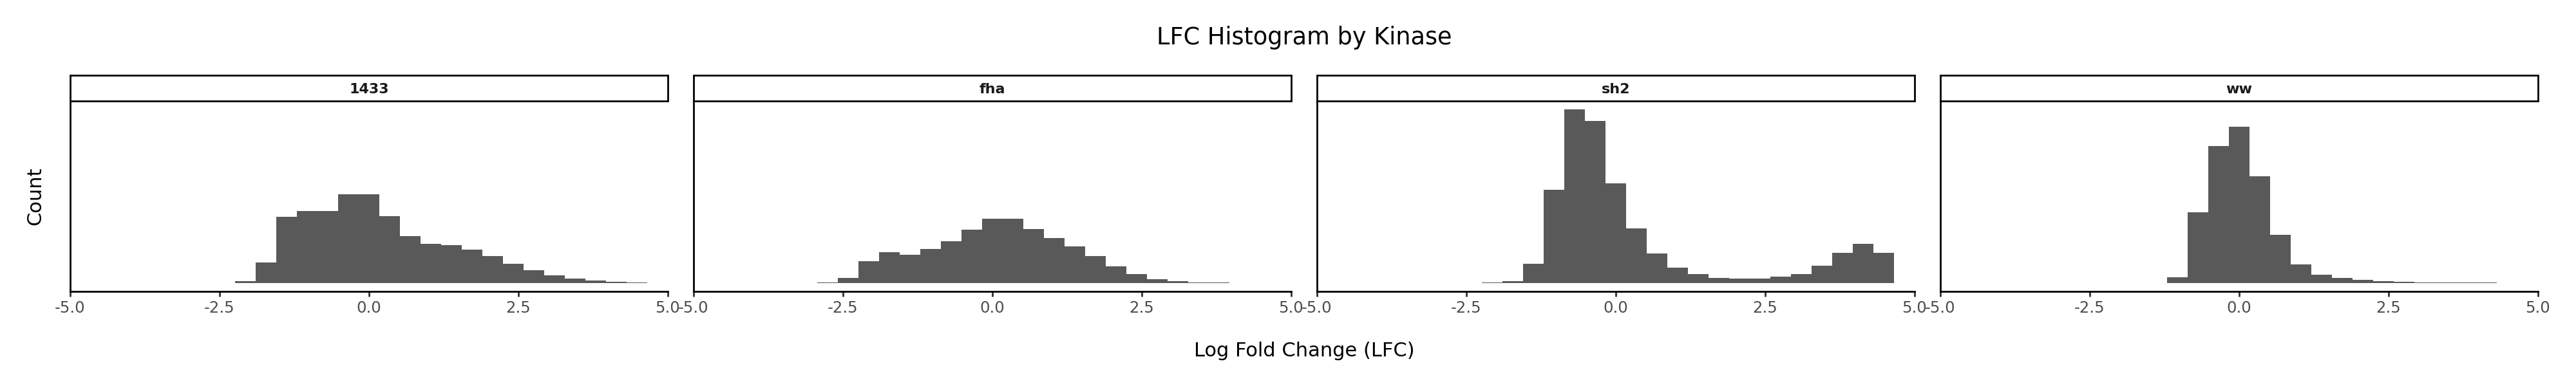

In [94]:
p = ( ggplot( dat_all_blib.dropna(subset=['kinase_name', 'LFC']), # keep it tidy 
              aes(x='LFC') ) + geom_histogram(bins=30) # adjust bins as you like 
      + facet_grid(cols=['paabd'], scales='free_y') 
      + labs( title='LFC Histogram by Kinase', x='Log Fold Change (LFC)', y='Count') 
      + theme_classic() 
      + theme(
        strip_text_y=element_text(size=8, weight='bold', rotation=0, ha='left', va='center'),
        strip_text_x=element_text(size=8, weight='bold')  # keep x-strip sizing consistent
    )
    )

p = (
    p
    + scale_x_continuous(limits=(-5,5), expand=(0, 0))
    + theme(
        axis_text_y=element_blank(),          # remove y tick labels
        axis_ticks_major_y=element_blank(),   # remove major y tick marks
        axis_ticks_minor_y=element_blank(),    # remove minor y tick marks
        figure_size=(20, 3)
    )
)
p

In [95]:
dat_all_blib.loc[dat_all_blib['Gene']=='ATGACTGGGTGGCGTTATG',:]

,id,num,neg|score,neg|p-value,neg|fdr,neg|rank,neg|goodsgrna,neg|lfc,pos|score,pos|p-value,...,substrate_aa,kinase_aa,kinase_type,kinase_name,kinase_acc,paabd,pre_1,mtx_1,pre_2,mtx_2
54134,ATGACTGGGTGGCGTTATG,1,0.9975,0.99749,0.999991,72391,0,3.2305,0.002498,0.002507,...,QGPSQTSTPTDVTAI,WLLSDILGQGATANVFRGRHKKTGDLFAIKVFNNISFLRPVDVQMR...,ST,TBK1_HUMAN,Q9UHD2,fha,76,960,230,1653
